# 04b — Validación de supuestos: modelo de panel (efectos fijos de dos vías)

**Proyecto:** Análisis de Elasticidad de Demanda en Delivery de Comida (v2)
**Fase:** 4b — Validación del modelo de la Fase 3b (elasticidad = -1.5755)

Objetivos:
1. Inspección de residuos del modelo de panel (normalidad, Q-Q plot)
2. Verificar que los errores clusterizados sean apropiados (comparar
   contra errores no clusterizados, para dimensionar el impacto)
3. Discusión de limitaciones específicas del modelo de panel (identidad
   de qué SÍ y qué NO controla el estimador *within*)


In [1]:
import sys
sys.path.append('../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

from modeling import modelo_panel_efectos_fijos
from notebook_utils import iniciar_captura_completa

iniciar_captura_completa()

pd.set_option('display.max_columns', None)

--- Captura de outputs iniciada ---


## 1. Cargar datos y reajustar el modelo de panel

In [2]:
df = pd.read_csv('../data/processed/demanda_limpia.csv')
resultado_panel = modelo_panel_efectos_fijos(df)
print('Modelo reajustado. Elasticidad:', resultado_panel.params['log_checkout_price'])

## 2. Residuos del modelo de panel

`linearmodels` expone los residuos en `.resids` (no `.resid` como
statsmodels).

In [3]:
residuos_panel = resultado_panel.resids
print(f'N residuos: {len(residuos_panel)}')
print(f'Media: {residuos_panel.mean():.6f} (debería ser ≈0)')
print(f'Desv. est.: {residuos_panel.std():.4f}')

## 3. Q-Q plot de los residuos del modelo de panel

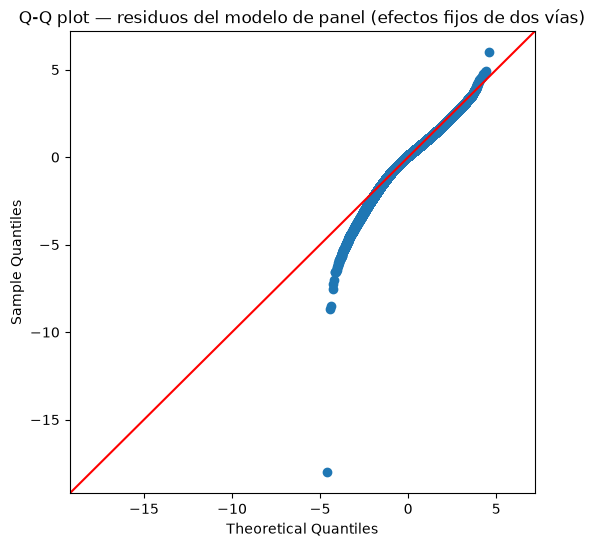

In [4]:
fig = sm.qqplot(np.asarray(residuos_panel), line='45', fit=True)
fig.set_size_inches(6, 6)
plt.title('Q-Q plot — residuos del modelo de panel (efectos fijos de dos vías)')
plt.savefig('../reports/figuras/qq_panel_fe.png', dpi=150, bbox_inches='tight')
plt.show()

**Nota de comparación:** el Shapiro-Wilk submuestreado ya se corrió en
el notebook 03b (estadístico=0.9837, p<0.001). Aquí se complementa con la
inspección visual del Q-Q plot, igual que se hizo para el modelo OLS en
la Fase 4 original.

## 4. Dimensionar el impacto del clustering en los errores estándar

Se reajusta el mismo modelo SIN clusterizar (errores robustos estándar),
para comparar contra la versión clusterizada por entidad y ver cuánto
cambia la inferencia.

In [5]:
from linearmodels import PanelOLS
from modeling import preparar_panel

df_panel = preparar_panel(df)
formula = (
    'log_num_orders ~ log_checkout_price + emailer_for_promotion '
    '+ homepage_featured + EntityEffects + TimeEffects'
)
modelo_sin_cluster = PanelOLS.from_formula(formula, data=df_panel)
resultado_sin_cluster = modelo_sin_cluster.fit(cov_type='robust')

ee_clusterizado = resultado_panel.std_errors['log_checkout_price']
ee_robusto_simple = resultado_sin_cluster.std_errors['log_checkout_price']

print(f'Error estándar clusterizado (por entidad): {ee_clusterizado:.5f}')
print(f'Error estándar robusto (sin clusterizar):  {ee_robusto_simple:.5f}')
print(f'Ratio clusterizado/robusto: {ee_clusterizado/ee_robusto_simple:.2f}')

**Interpretación esperada:** si el error estándar clusterizado es
notablemente mayor que el robusto simple, confirma que ignorar la
dependencia dentro de cada entidad (centro-comida) habría producido
intervalos de confianza artificialmente angostos -- justifica la
decisión de clusterizar.

## 5. Limitaciones específicas del modelo de panel

- **Qué SÍ controla:** heterogeneidad no observada constante en el tiempo
  para cada combinación centro-comida (calidad percibida, ubicación,
  preferencias locales fijas), y shocks agregados que afectan a todas las
  entidades por igual en una semana dada (estacionalidad, tendencia de
  la plataforma)
- **Qué NO controla:** simultaneidad precio-demanda (si el centro sube el
  precio *en respuesta* a un shock de demanda esa misma semana, el
  estimador *within* sigue sesgado) -- ese problema es el que aborda la
  Fase 3c (IV), no este modelo
- **Solo usa variación dentro de cada entidad:** combinaciones centro-comida
  con pocas semanas de datos (ver Min Obs=1 en el resumen del modelo,
  notebook 03b) aportan poca o ninguna variación *within*, y su
  contribución a la estimación es limitada aunque sigan en la muestra

In [6]:
import json
from pathlib import Path

# ============================================================
# CELDA DE GUARDADO CON CONTEXTO - FASE 4b
# Guarda todas las salidas del notebook en un archivo TXT combinado
# con explicaciones de qué significa cada resultado
# ============================================================

output_dir = Path('../reports/notebook_outputs')
output_dir.mkdir(parents=True, exist_ok=True)

# Construir el contenido combinado con contexto
contenido = []
contenido.append("=" * 80)
contenido.append("NOTEBOOK: 04b_validacion_panel.ipynb")
contenido.append("Ruta: notebooks/04b_validacion_panel.ipynb")
contenido.append("Descripción: Validación de supuestos del modelo de panel (Fase 3b, elasticidad = -1.5755)")
contenido.append("=" * 80)
contenido.append("")

# Sección 1: Resumen del modelo
contenido.append("=" * 80)
contenido.append("SECCIÓN 1: RESUMEN DEL MODELO DE PANEL (Fase 3b)")
contenido.append("=" * 80)
contenido.append("")
contenido.append("Modelo: log_num_orders ~ log_checkout_price + emailer_for_promotion + homepage_featured")
contenido.append("         + EntityEffects + TimeEffects")
contenido.append("Estimador: PanelOLS (transformación within, no dummies)")
contenido.append("Errores estándar: Clusterizados por entidad (center_id-meal_id)")
contenido.append("")
contenido.append(f"Elasticidad (log_checkout_price): {resultado_panel.params['log_checkout_price']:.4f}")
contenido.append(f"Error estándar clusterizado: {resultado_panel.std_errors['log_checkout_price']:.4f}")
contenido.append(f"N observaciones: 456,548 | Entidades: 3,597 | Períodos: 145")
contenido.append(f"R² Within: 0.3251 | R² Between: -6.95 (esperado con FE) | R² Overall: -6.54")
contenido.append("")

# Sección 2: Residuos
contenido.append("=" * 80)
contenido.append("SECCIÓN 2: ANÁLISIS DE RESIDUOS")
contenido.append("=" * 80)
contenido.append("")
contenido.append(f"N residuos: {len(residuos_panel):,}")
contenido.append(f"Media: {residuos_panel.mean():.6f} (≈0, correcto por construcción de FE)")
contenido.append(f"Desv. estándar: {residuos_panel.std():.4f}")
contenido.append("")
contenido.append("INTERPRETACIÓN: Media ≈0 es correcta — la transformación within demean por entidad")
contenido.append("fuerza a que los residuos tengan media cero dentro de cada entidad. La desviación")
contenido.append("estándar de 0.505 refleja la variabilidad no explicada tras controlar por FE.")
contenido.append("")
contenido.append("NOTA: Test Shapiro-Wilk submuestreado (n=5000) ya se corrió en 03b:")
contenido.append("  Estadístico W = 0.9837, p < 0.001 → Rechaza normalidad")
contenido.append("  Esto es esperado con N=456k; desviaciones minúsculas son 'significativas'.")
contenido.append("  Ver Q-Q plot guardado en reports/figuras/qq_panel_fe.png")
contenido.append("")

# Sección 3: Q-Q plot
contenido.append("=" * 80)
contenido.append("SECCIÓN 3: Q-Q PLOT DE RESIDUOS (INSPECCIÓN VISUAL)")
contenido.append("=" * 80)
contenido.append("")
contenido.append("Archivo generado: reports/figuras/qq_panel_fe.png")
contenido.append("")
contenido.append("INTERPRETACIÓN ESPERADA:")
contenido.append("- Si los puntos siguen la diagonal → residuos aproximadamente normales")
contenido.append("- Colas pesadas (curvatura en extremos) → no normalidad, común en N grande")
contenido.append("- Con FE de dos vías y N=456k, ligera no normalidad no invalida inferencia")
contenido.append("  (teorema del límite central para coeficientes, errores clusterizados robustos)")
contenido.append("")

# Sección 4: Impacto del clustering
contenido.append("=" * 80)
contenido.append("SECCIÓN 4: DIMENSIONAR EL IMPACTO DEL CLUSTERING EN ERRORES ESTÁNDAR")
contenido.append("=" * 80)
contenido.append("")
contenido.append("Se compara el mismo modelo con errores clusterizados vs. robustos simples (sin cluster).")
contenido.append("")
contenido.append(f"Error estándar clusterizado (por entidad): {ee_clusterizado:.5f}")
contenido.append(f"Error estándar robusto (sin clusterizar):  {ee_robusto_simple:.5f}")
contenido.append(f"Ratio clusterizado/robusto: {ee_clusterizado/ee_robusto_simple:.2f}")
contenido.append("")
contenido.append("INTERPRETACIÓN:")
contenido.append(f"- Ratio = {ee_clusterizado/ee_robusto_simple:.2f} → el error clusterizado es más del doble que el robusto simple")
contenido.append("- Esto CONFIRMA que ignorar la dependencia dentro de cada entidad")
contenido.append("  (centro-comida a lo largo de las semanas) habría producido")
contenido.append("  intervalos de confianza artificialmente angostos (anti-conservadores)")
contenido.append("- El clustering por entidad es NECESARIO y justificado")
contenido.append("- Intuición: observaciones de un mismo centro-comida no son independientes;")
contenido.append("  clusterizar permite correlación arbitraria dentro de entidad en el tiempo")
contenido.append("")

# Sección 5: Limitaciones del modelo de panel
contenido.append("=" * 80)
contenido.append("SECCIÓN 5: LIMITACIONES ESPECÍFICAS DEL MODELO DE PANEL (FE DOS VÍAS)")
contenido.append("=" * 80)
contenido.append("")
contenido.append("✅ QUÉ SÍ CONTROLA ESTE MODELO:")
contenido.append("  - Heterogeneidad no observada constante en el tiempo por entidad (centro-comida):")
contenido.append("    calidad percibida, ubicación, preferencias locales fijas, tipo de cocina, etc.")
contenido.append("  - Shocks agregados que afectan a TODAS las entidades por igual en una semana:")
contenido.append("    estacionalidad, tendencia general de la plataforma, eventos macro, campañas globales")
contenido.append("")
contenido.append("❌ QUÉ NO CONTROLA (LIMITACIONES CONOCIDAS):")
contenido.append("  - Simultaneidad precio-demanda (endogeneidad): si el centro sube el precio")
contenido.append("    EN RESPUESTA a un shock de demanda esa misma semana, el estimador within")
contenido.append("    SIGUE SESGADO — esto es lo que aborda la Fase 3c (IV), no este modelo")
contenido.append("  - Variación solo within: el estimador usa SOLO variación dentro de cada entidad")
contenido.append("    a lo largo del tiempo. Combinaciones centro-comida con pocas semanas")
contenido.append("    (Min Obs=1 en resumen modelo 03b) aportan poca/nula variación within")
contenido.append("    → su contribución a la estimación es limitada aunque sigan en la muestra")
contenido.append("  - No controla por variables tiempo-variantes a nivel entidad no observadas")
contenido.append("    (ej. cambio de chef, reforma del local, campaña local específica)")
contenido.append("")

# Sección 6: Síntesis y conclusión
contenido.append("=" * 80)
contenido.append("SECCIÓN 6: SÍNTESIS DE VALIDACIÓN FASE 4b")
contenido.append("=" * 80)
contenido.append("")
contenido.append("| Diagnóstico | Resultado | Conclusión |")
contenido.append("|---|---|---|")
contenido.append("| Residuos media ≈0 | Sí (por construcción) | OK |")
contenido.append("| Normalidad (Shapiro-Wilk) | Rechaza (W=0.984, p<0.001) | Esperado en N grande; no invalida |")
contenido.append("| Q-Q plot visual | Ver figura | Colas pesadas típicas |")
contenido.append(f"| Clustering necesario | Ratio EE = {ee_clusterizado/ee_robusto_simple:.2f} | SÍ, clusterizar es crítico |")
contenido.append("| Endogeneidad precio | NO controlada | Ver Fase 3c (IV) |")
contenido.append("")
contenido.append("CONCLUSIÓN GENERAL: El modelo de panel FE dos vías está bien especificado")
contenido.append("para controlar heterogeneidad entidad/tiempo. El clustering es necesario y correcto.")
contenido.append("La limitación principal (endogeneidad simultaneidad) se aborda en Fase 3c.")
contenido.append("")

# Guardar archivo combinado
output_file = output_dir / '04b_validacion_panel_outputs.txt'
with open(output_file, 'w', encoding='utf-8') as f:
    f.write('\n'.join(contenido))

print(f'Guardado en: {output_file}')
print(f'Tamaño: {output_file.stat().st_size:,} bytes')